# Sesión 7 · Notebook de clase · Limpieza y preparación de datos

**Fundamentos de Ciencia de Datos e IA (CDIAG1003)** · Semana 4 · Unidad 2: temas 2.5 (limpieza), 2.6 (datos faltantes) y 2.7 (estandarización, texto y categóricos).

Hoy el conjunto de datos es `datos/ventas_sucio.csv`: son las **mismas 200 ventas** de la tienda que ya conoce de las sesiones 4 y 5, pero tal como suelen llegar en la vida real: filas repetidas, ciudades escritas de tres maneras, precios con `$`, fechas en dos formatos, valores faltantes y un error de digitación. Al terminar la sesión, su tabla limpia debe dar el **mismo ingreso total que en la sesión 5: 7 424.8**.

**Cómo trabajar con este notebook**
- Ejecute las celdas en orden (`Shift + Enter`). Cuando algo se rompa, use *Kernel → Restart Kernel and Run All Cells*.
- En los ejercicios **Su turno**, reemplace los `...` por su código. La celda siguiente comprueba el resultado con `assert`: si no imprime nada, está bien.
- Después de cada ejercicio hay una celda «Para continuar con la misma tabla»: ejecútela aunque su respuesta haya sido correcta; así todo el grupo sigue con los mismos datos.
- Las salidas de la versión resuelta están en pandas 3: el texto aparece con tipo `str`. En pandas 2 aparece como `object`; es lo mismo.

In [184]:
import os
import numpy as np
import pandas as pd

print("pandas", pd.__version__, "| NumPy", np.__version__)

pandas 3.1.0 | NumPy 2.5.4


## 1. Diagnóstico: medir antes de arreglar

La limpieza empieza con cuatro preguntas: ¿cuántas filas y columnas hay?, ¿de qué tipo es cada columna?, ¿cuántos valores faltan? y ¿hay filas repetidas? pandas responde cada una con un método.

In [185]:
v = pd.read_csv("datos/ventas_sucio.csv")
v.shape

(208, 8)

In [186]:
v.head(8)

,fecha,producto,categoria,cantidad,precio_unitario,ciudad,metodo_pago,notas
0,2026-01-02,Sartén,Hogar,1,18.0,Quito,Tarjeta,NaN
1,2026-01-02,Mouse,Electronica,1,15.0,MACHALA,Efectivo,NaN
2,2026-01-02,Mouse,Electronica,1,15.0,MACHALA,Efectivo,NaN
3,2026-01-03,Galletas,Alimentos,2,1.8,Quito,Tarjeta,NaN
4,2026-01-03,Cuaderno,Papelería,2,2.5,Guayaquil,transferencia,NaN
5,2026-01-04,Cargador,Electronica,3,12.5,Guayaquil,Tarjeta,NaN
6,2026-01-04,Cuaderno,Papelería,4,2.5,Guayaquil,Tarjeta,NaN
7,2026-01-04,Galletas,Alimentos,1,1.8,guayaquil,Efectivo,NaN


In [187]:
# Tipos y valores no nulos por columna. Observe: precio_unitario NO es numérico y notas está vacía.
v.info()

<class 'pandas.DataFrame'>
RangeIndex: 208 entries, 0 to 207
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   fecha            208 non-null    str    
 1   producto         208 non-null    str    
 2   categoria        208 non-null    str    
 3   cantidad         208 non-null    int64  
 4   precio_unitario  203 non-null    str    
 5   ciudad           202 non-null    str    
 6   metodo_pago      198 non-null    str    
 7   notas            0 non-null      float64
dtypes: float64(1), int64(1), str(6)
memory usage: 13.1 KB


In [188]:
# Faltantes por columna
v.isna().sum()

fecha                0
producto             0
categoria            0
cantidad             0
precio_unitario      5
ciudad               6
metodo_pago         10
notas              208
dtype: int64

In [189]:
# Filas repetidas exactas (todas las columnas iguales)
v.duplicated().sum()

np.int64(8)

In [190]:
# value_counts muestra las variantes de una columna de texto. dropna=False incluye los faltantes.
v["ciudad"].value_counts(dropna=False)

ciudad
Guayaquil      60
Quito          47
Cuenca         33
Manta          15
Machala        10
 Guayaquil      6
NaN             6
quito           6
QUITO           5
guayaquil       4
GUAYAQUIL       4
MACHALA         2
CUENCA          2
UIO             2
 Quito          2
manta           1
machala         1
CUE             1
GYE             1
Name: count, dtype: int64

Hay cinco ciudades, pero pandas cuenta **18 valores distintos**: mayúsculas, minúsculas, espacios alrededor y abreviaturas. Para pandas, `"Quito"`, `"quito"` y `" Quito "` son tres categorías diferentes. Ese es el problema más frecuente en datos reales.

### Su turno 1.1 · 3 min
Responda con código: (a) cuántos valores **distintos** hay en `categoria` y en `metodo_pago` (`nunique()`), y (b) cuántos valores faltan **en toda la tabla** (sume los faltantes de todas las columnas).

In [191]:
# TODO: reemplace los ... por su código
n_categoria = v["categoria"].nunique()
n_pago = v["metodo_pago"].nunique()
total_faltantes = v.isna().sum().sum()
print(n_categoria, n_pago, total_faltantes)

17 10 229


In [192]:
assert n_categoria == 17, "categoria: cuente los valores distintos con nunique()"
assert n_pago == 10, "metodo_pago: nunique() no cuenta los faltantes"
assert total_faltantes == 229, "total: isna().sum() da una Series por columna; súmela otra vez"
print("Correcto: 4 categorías reales se ven como", n_categoria, "y hay", total_faltantes, "faltantes (208 de ellos en la columna vacía notas).")

Correcto: 4 categorías reales se ven como 17 y hay 229 faltantes (208 de ellos en la columna vacía notas).


## 2. Duplicados y columnas vacías

Una fila duplicada **exacta** casi siempre es un error de carga (el mismo archivo pegado dos veces, un formulario enviado dos veces). `drop_duplicates()` la elimina y conserva la primera aparición. Una columna completamente vacía no aporta nada: se elimina.

In [193]:
# Ver las filas repetidas: keep=False marca todas las copias, no solo la segunda
v[v.duplicated(keep=False)].sort_values(["fecha", "producto"]).head(6)

,fecha,producto,categoria,cantidad,precio_unitario,ciudad,metodo_pago,notas
89,12/02/2026,Mouse,electrónica,2,$15.0,Cuenca,Tarjeta,NaN
90,12/02/2026,Mouse,electrónica,2,$15.0,Cuenca,Tarjeta,NaN
42,20/01/2026,Cargador,Electrónica,1,12.5,Quito,efectivo,NaN
43,20/01/2026,Cargador,Electrónica,1,12.5,Quito,efectivo,NaN
1,2026-01-02,Mouse,Electronica,1,15.0,MACHALA,Efectivo,NaN
2,2026-01-02,Mouse,Electronica,1,15.0,MACHALA,Efectivo,NaN


In [194]:
# Columnas con TODOS los valores faltantes
v.columns[v.isna().all()]

Index(['notas'], dtype='str')

### Su turno 2.1 · 3 min
Cree `v2` sin las filas duplicadas y sin la columna `notas`. Debe quedar con 200 filas y 7 columnas. Use `drop_duplicates()` y `drop(columns=...)`.

In [195]:
# TODO: reemplace los ... por su código
v2 = v.drop_duplicates().drop(columns=v.columns[v.isna().all()])
v2.shape

(200, 7)

In [196]:
assert v2.shape == (200, 7), f"se esperaban (200, 7) y hay {v2.shape}"
assert "notas" not in v2.columns and v2.duplicated().sum() == 0
print("Correcto: 200 ventas, sin repetidas y sin la columna vacía.")

Correcto: 200 ventas, sin repetidas y sin la columna vacía.


In [197]:
# Para continuar con la misma tabla (ejecute siempre esta celda)
v = v.drop_duplicates().drop(columns=["notas"]).reset_index(drop=True)
v.shape

(200, 7)

## 3. Texto: espacios, mayúsculas y sinónimos

Las columnas de texto se limpian con el accesor `.str`, que aplica un método de cadena a toda la columna de una vez:

| Problema | Método | Ejemplo |
| :-- | :-- | :-- |
| espacios alrededor | `.str.strip()` | `" Quito "` → `"Quito"` |
| mayúsculas y minúsculas mezcladas | `.str.lower()`, `.str.upper()`, `.str.title()`, `.str.capitalize()` | `"QUITO"` → `"Quito"` |
| abreviaturas o sinónimos | `.replace({viejo: nuevo})` | `"Uio"` → `"Quito"` |
| un fragmento dentro del texto | `.str.replace(viejo, nuevo)` | `"$12.5"` → `"12.5"` |

El orden importa: primero se quitan espacios, luego se unifica la caja y al final se reemplazan los sinónimos que quedaron.

In [198]:
# Paso a paso con ciudad
paso1 = v["ciudad"].str.strip()              # sin espacios
paso2 = paso1.str.title()                    # Primera Letra En Mayúscula
paso2.value_counts(dropna=False)

ciudad
Guayaquil    73
Quito        56
Cuenca       34
Manta        16
Machala      12
NaN           6
Uio           1
Cue           1
Gye           1
Name: count, dtype: int64

In [199]:
# Quedan las abreviaturas, ahora en formato Título: las traducimos con un diccionario
abreviaturas = {"Gye": "Guayaquil", "Uio": "Quito", "Cue": "Cuenca", "Mec": "Manta", "Mch": "Machala"}
v["ciudad"] = paso2.replace(abreviaturas)
v["ciudad"].value_counts(dropna=False)

ciudad
Guayaquil    74
Quito        57
Cuenca       35
Manta        16
Machala      12
NaN           6
Name: count, dtype: int64

Cinco ciudades y 6 faltantes: la columna ya es confiable. Los faltantes se deciden en la sección 5.

### Su turno 3.1 · 5 min
Limpie `categoria` y `producto` de modo que `categoria` tenga **4** valores (`Electrónica`, `Hogar`, `Alimentos`, `Papelería`) y `producto` **10**. Pista para las tildes: después de `strip()` y `lower()`, use `replace({"electronica": "electrónica", "papeleria": "papelería"})` y termine con `.str.capitalize()`.

In [200]:
# TODO: reemplace los ... por su código
categoria_limpia = v["categoria"].str.strip().str.lower().replace({"electronica": "electrónica", "papeleria": "papelería"}).str.capitalize()
producto_limpio = v["producto"].str.strip().str.lower().replace({"electronica": "electrónica", "papeleria": "papelería"}).str.capitalize()
print(categoria_limpia.nunique(), producto_limpio.nunique())
print(sorted(categoria_limpia.unique()))

4 10
['Alimentos', 'Electrónica', 'Hogar', 'Papelería']


In [201]:
assert set(categoria_limpia) == {"Electrónica", "Hogar", "Alimentos", "Papelería"}, f"categorias: {sorted(categoria_limpia.unique())}"
assert producto_limpio.nunique() == 10, f"producto tiene {producto_limpio.nunique()} valores distintos; deben ser 10"
assert "Café" in set(producto_limpio) and "Audífonos" in set(producto_limpio), "revise las tildes: capitalize() las conserva"
print("Correcto: 4 categorías y 10 productos.")

Correcto: 4 categorías y 10 productos.


In [202]:
# Para continuar con la misma tabla
cat = v["categoria"].str.strip().str.lower()
v["categoria"] = cat.replace({"electronica": "electrónica", "papeleria": "papelería"}).str.capitalize()
v["producto"] = v["producto"].str.strip().str.capitalize()
v["metodo_pago"].value_counts(dropna=False)

metodo_pago
EFECTIVO         32
TARJETA          32
Tarjeta          24
efectivo         21
Efectivo         19
efectivo         19
tarjeta          17
transf.          13
transferencia     9
NaN               9
Transferencia     5
Name: count, dtype: int64

### Su turno 3.2 · 3 min
`metodo_pago` debe quedar con **tres** valores en minúsculas: `efectivo`, `tarjeta`, `transferencia` (más los faltantes, que todavía no se tocan). Observe que `transf.` es una abreviatura.

In [203]:
v["metodo_pago"].unique()

<StringArray>
[      'Tarjeta',      'Efectivo', 'transferencia',       'tarjeta',
      'efectivo',     'efectivo ',      'EFECTIVO', 'Transferencia',
       'TARJETA',       'transf.',             nan]
Length: 11, dtype: str

In [204]:
# TODO: reemplace los ... por su código
pago_limpio = v["metodo_pago"].str.lower().str.strip().str.replace({"transf.":"transferencia"})
pago_limpio.value_counts(dropna=False)

metodo_pago
efectivo         91
tarjeta          73
transferencia    27
NaN               9
Name: count, dtype: int64

In [205]:
assert set(pago_limpio.dropna()) == {"efectivo", "tarjeta", "transferencia"}, f"valores: {sorted(pago_limpio.dropna().unique())}"
assert pago_limpio.isna().sum() == 9, "los faltantes se deciden en la sección 5; aquí deben seguir siendo 9"
print("Correcto: tres métodos de pago.")

Correcto: tres métodos de pago.


In [206]:
# Para continuar con la misma tabla
v["metodo_pago"] = v["metodo_pago"].str.strip().str.lower().replace({"transf.": "transferencia"})

## 4. Tipos: de texto a número y a fecha

`precio_unitario` se leyó como texto porque algunas celdas traen `$` y otras usan coma decimal (`12,5`). Con una sola celda «rara», pandas convierte **toda** la columna a texto, y entonces no se puede sumar ni promediar. La receta: quitar los caracteres sobrantes con `.str.replace`, y convertir con `pd.to_numeric(..., errors="coerce")`, que pone `NaN` donde no puede convertir en lugar de detenerse con un error.

In [207]:
# ¿Qué valores tienen "$" o coma?
precio_txt = v["precio_unitario"]
precio_txt[precio_txt.str.contains(r"\$|,", na=False)].head(8)

9      $6.5
24     $2.5
40      3,2
41     $0.6
44     15,0
50     $1.8
51    $25.0
62    $12.5
Name: precio_unitario, dtype: str

In [208]:
limpio = precio_txt.str.replace("$", "", regex=False).str.replace(",", ".", regex=False)
v["precio_unitario"] = pd.to_numeric(limpio, errors="coerce")
v["precio_unitario"].describe()

count    195.000000
mean      12.914872
std       16.932207
min        0.600000
25%        2.500000
50%        6.500000
75%       18.000000
max      180.000000
Name: precio_unitario, dtype: float64

Ya es numérica (`float64`): se puede ver el mínimo, el máximo y el promedio. El máximo (180) es sospechoso; lo trataremos en la sección 6. Los 5 faltantes siguen ahí (`count` = 195).

**Fechas.** La columna `fecha` mezcla `2026-01-04` (año-mes-día) con `04/01/2026` (día/mes/año). Si se convierte sin indicar el formato, pandas adivina con el primer valor y puede **intercambiar día y mes sin avisar** cuando el día es 12 o menos. La forma segura: convertir cada formato por separado con `format=` y `errors="coerce"`, y combinar los resultados con `fillna`.

In [209]:
v["fecha"].sample(6, random_state=4)

11     2026-01-05
99     2026-02-16
128    2026-03-04
175    2026-03-21
1      2026-01-02
111    23/02/2026
Name: fecha, dtype: str

### Su turno 4.1 · 4 min
Convierta `fecha` a tipo fecha (`datetime64`) sin perder ninguna: primero el formato `"%Y-%m-%d"`, luego `"%d/%m/%Y"`, y combine con `fillna`. Al final no debe quedar ningún faltante y la fecha mínima debe ser el 2 de enero de 2026.

In [210]:
# TODO: reemplace los ... por su código
iso = pd.to_datetime(v["fecha"], format="%Y-%m-%d", errors="coerce")
dmy = pd.to_datetime(v["fecha"], format="%d/%m/%Y", errors="coerce")
fecha_ok = iso.fillna(dmy)
print(fecha_ok.dtype, fecha_ok.isna().sum(), fecha_ok.min().date(), fecha_ok.max().date())

datetime64[us] 0 2026-01-02 2026-03-31


In [211]:
assert str(fecha_ok.dtype).startswith("datetime64"), f"el tipo es {fecha_ok.dtype}; debe ser datetime64"
assert fecha_ok.isna().sum() == 0, "quedaron fechas sin convertir: revise el segundo formato"
assert fecha_ok.min() == pd.Timestamp("2026-01-02") and fecha_ok.max() == pd.Timestamp("2026-03-31"), "día y mes intercambiados en alguna fecha"
print("Correcto: 200 fechas entre el 2 de enero y el 31 de marzo de 2026.")

Correcto: 200 fechas entre el 2 de enero y el 31 de marzo de 2026.


In [212]:
# Para continuar con la misma tabla
iso = pd.to_datetime(v["fecha"], format="%Y-%m-%d", errors="coerce")
dmy = pd.to_datetime(v["fecha"], format="%d/%m/%Y", errors="coerce")
v["fecha"] = iso.fillna(dmy)
v.dtypes

fecha              datetime64[us]
producto                      str
categoria                     str
cantidad                    int64
precio_unitario           float64
ciudad                        str
metodo_pago                   str
dtype: object

## 5. Faltantes: ver, decidir, rellenar o quitar

No hay una regla única. Antes de rellenar o borrar hay que preguntar **por qué** falta el dato y **para qué** se usará la columna:

| Situación | Decisión típica | Código |
| :-- | :-- | :-- |
| el valor se puede deducir de otras columnas | recuperarlo | `fillna(valor_deducido)` |
| columna categórica, el faltante es informativo | nueva categoría | `fillna("Sin dato")` |
| columna numérica, pocos faltantes al azar | mediana (o media) | `fillna(col.median())` |
| la fila no sirve sin ese dato | eliminar la fila | `dropna(subset=[col])` |
| casi toda la columna falta | eliminar la columna | `drop(columns=col)` |

En esta tienda, cada producto tiene **un solo precio**: el precio faltante se recupera mirando el precio de las otras ventas del mismo producto. Ese es el mejor caso: no se inventa nada.

In [213]:
v.isna().sum()

fecha              0
producto           0
categoria          0
cantidad           0
precio_unitario    5
ciudad             6
metodo_pago        9
dtype: int64

In [214]:
# ¿Qué filas tienen precio faltante?
v[v["precio_unitario"].isna()]

,fecha,producto,categoria,cantidad,precio_unitario,ciudad,metodo_pago
20,2026-01-09,Cargador,Electrónica,2,NaN,Manta,tarjeta
35,2026-01-18,Sartén,Hogar,3,NaN,Guayaquil,efectivo
52,2026-01-26,Café,Alimentos,3,NaN,Guayaquil,tarjeta
175,2026-03-21,Licuadora,Hogar,2,NaN,Guayaquil,tarjeta
196,2026-03-30,Cargador,Electrónica,1,NaN,Quito,tarjeta


In [215]:
# Precio de referencia por producto: la mediana de las ventas de ese producto.
# transform devuelve una Series alineada con cada fila (del tamaño de v), lista para fillna.
precio_ref = v.groupby("producto")["precio_unitario"].transform("median")

### Su turno 5.1 · 5 min
Resuelva los tres faltantes: `precio_unitario` con el precio de referencia (`precio_ref`), `ciudad` con `"Sin dato"` y `metodo_pago` con `"desconocido"`. Al final la tabla no debe tener ningún faltante.

In [216]:
# TODO: reemplace los ... por su código
w = v.copy()          # trabaje sobre la copia w
w["precio_unitario"] = w["precio_unitario"].fillna(precio_ref)
w["ciudad"] = w["ciudad"].fillna("Sin dato")
w["metodo_pago"] = w["metodo_pago"].fillna("desconocido")
w.isna().sum()

fecha              0
producto           0
categoria          0
cantidad           0
precio_unitario    0
ciudad             0
metodo_pago        0
dtype: int64

In [217]:
assert w.isna().sum().sum() == 0, "todavía hay faltantes"
assert (w["ciudad"] == "Sin dato").sum() == 6, "ciudad: 6 filas deben decir 'Sin dato'"
assert (w["metodo_pago"] == "desconocido").sum() == 9
assert np.isclose(w.loc[w["producto"] == "Sartén", "precio_unitario"].min(), 18.0), "el precio recuperado debe ser el del producto"
print("Correcto: sin faltantes. Precio recuperado, no inventado; las dos columnas de texto dicen explícitamente que no hay dato.")

Correcto: sin faltantes. Precio recuperado, no inventado; las dos columnas de texto dicen explícitamente que no hay dato.


In [218]:
# Para continuar con la misma tabla
v["precio_unitario"] = v["precio_unitario"].fillna(precio_ref)
v["ciudad"] = v["ciudad"].fillna("Sin dato")
v["metodo_pago"] = v["metodo_pago"].fillna("desconocido")

## 6. Valores atípicos: detectar y decidir

Un valor atípico (*outlier*) es un dato muy lejos del resto. Puede ser un **error** (un cero de más) o un dato **real e importante** (la venta más grande del año). Detectarlo es mecánico; decidir qué hacer requiere conocer el negocio.

Tres formas de verlo: `describe()` (mínimo y máximo), un diagrama de caja (*boxplot*) y la regla del rango intercuartílico: es atípico lo que queda fuera de `[Q1 − 1.5·IQR, Q3 + 1.5·IQR]`.

In [ ]:
v[v["producto"] == ""]

In [219]:
v["precio_unitario"].describe()

count    200.000000
mean      13.064500
std       16.881505
min        0.600000
25%        2.500000
50%       12.500000
75%       18.000000
max      180.000000
Name: precio_unitario, dtype: float64

In [220]:
atipico = v["precio_unitario"] > 100
v.loc[atipico, "precio_unitario"] = precio_ref[atipico]
v["precio_unitario"].max()
# 45.0


np.float64(45.0)

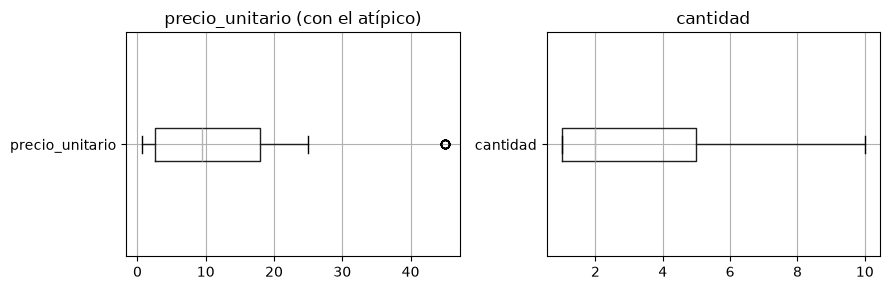

In [221]:
import matplotlib.pyplot as plt

fig, ejes = plt.subplots(1, 2, figsize=(9, 3))
v.boxplot(column="precio_unitario", ax=ejes[0], vert=False)
ejes[0].set_title("precio_unitario (con el atípico)")

v.boxplot(column="cantidad", ax=ejes[1], vert=False)
ejes[1].set_title("cantidad")
plt.tight_layout()

In [222]:
q1, q3 = v["precio_unitario"].quantile([0.25, 0.75])
iqr = q3 - q1
limite_sup = q3 + 1.5 * iqr
print("Q1:", q1, "Q3:", q3, "IQR:", iqr, "límite superior:", limite_sup)
v[v["precio_unitario"] > limite_sup]

Q1: 2.5 Q3: 18.0 IQR: 15.5 límite superior: 41.25


,fecha,producto,categoria,cantidad,precio_unitario,ciudad,metodo_pago
54,2026-01-27,Licuadora,Hogar,1,45.0,Quito,tarjeta
57,2026-01-28,Licuadora,Hogar,6,45.0,Guayaquil,tarjeta
58,2026-01-28,Licuadora,Hogar,2,45.0,Guayaquil,tarjeta
68,2026-02-05,Licuadora,Hogar,1,45.0,Quito,efectivo
69,2026-02-05,Licuadora,Hogar,3,45.0,Guayaquil,efectivo
72,2026-02-07,Licuadora,Hogar,5,45.0,Guayaquil,transferencia
114,2026-02-23,Licuadora,Hogar,5,45.0,Quito,efectivo
115,2026-02-24,Licuadora,Hogar,3,45.0,Machala,efectivo
135,2026-03-07,Licuadora,Hogar,2,45.0,Guayaquil,tarjeta
137,2026-03-07,Licuadora,Hogar,3,45.0,Machala,efectivo


Un paquete de galletas a 180 dólares, cuando las demás galletas cuestan 1.8: es un **error de digitación** (dos ceros de más), no una venta real. La corrección honesta es devolverle el precio del producto, y dejar constancia de la decisión en una celda de texto.

### Su turno 6.1 · 3 min
Corrija el valor atípico: en las filas donde `precio_unitario` es mayor que 100, reemplácelo por el precio de referencia del producto (`precio_ref`). Use `v.loc[condición, columna] = ...`.

In [223]:
# TODO: reemplace los ... por su código
w = v.copy()          # trabaje sobre la copia w
atipico = w["precio_unitario"] > 100
w.loc[atipico, "precio_unitario"] = ...
w["precio_unitario"].max()

TypeError: Invalid value 'Ellipsis' for dtype 'float64'

In [ ]:
assert w["precio_unitario"].max() == 45.0, f"el máximo debe ser 45.0 (la licuadora) y es {w['precio_unitario'].max()}"
assert np.isclose(w.loc[37, "precio_unitario"], 1.8), "el precio corregido debe ser el del producto"
print("Correcto: el precio máximo vuelve a ser el de la licuadora.")

In [ ]:
# Para continuar con la misma tabla
atipico = v["precio_unitario"] > 100
v.loc[atipico, "precio_unitario"] = precio_ref[atipico]

## 7. Categóricos y estandarización

**Tipo `category`.** Una columna de texto con pocos valores distintos (ciudad, categoría, método de pago) se puede declarar categórica con `astype("category")`. Ocupa menos memoria, deja claro cuáles son los valores válidos y permite declarar un **orden** (bajo < medio < alto) cuando la variable es ordinal.

In [ ]:
v["categoria"] = v["categoria"].astype("category")
v["ciudad"] = v["ciudad"].astype("category")
print(v["categoria"].cat.categories.tolist())
v.dtypes

In [ ]:
# Una categórica ORDINAL: tamaño de la venta según la cantidad (pequeña < mediana < grande)
tamano = pd.Categorical(np.where(v["cantidad"] <= 2, "pequeña", np.where(v["cantidad"] <= 5, "mediana", "grande")),
                        categories=["pequeña", "mediana", "grande"], ordered=True)
v["tamano"] = tamano
v["tamano"].value_counts().sort_index()

**Estandarización.** Hasta aquí estandarizamos *formatos*: una sola forma de escribir cada ciudad, un solo tipo por columna, una sola forma de fecha. También existe la estandarización *numérica*: llevar columnas con escalas distintas (precio en dólares, cantidad en unidades) a una escala común para poder compararlas o medir distancias entre filas. Dos recetas que se usan en la Unidad 4:

- **Puntaje z**: `(x − media) / desviación`. Cada columna queda con media 0 y desviación 1.
- **Min–max**: `(x − mín) / (máx − mín)`. Cada columna queda entre 0 y 1.

Ninguna cambia el orden de los valores; solo la escala.

In [ ]:
v["ingreso"] = v["cantidad"] * v["precio_unitario"]
num = v[["cantidad", "precio_unitario", "ingreso"]]
z = (num - num.mean()) / num.std()
minmax = (num - num.min()) / (num.max() - num.min())
pd.DataFrame({"z: media": z.mean().round(3), "z: desv.": z.std().round(3),
              "minmax: mín": minmax.min(), "minmax: máx": minmax.max()})

### Su turno 7.1 · 3 min
La prueba final: con la tabla limpia, el ingreso total debe ser exactamente el de la sesión 5. Calcule el total y guarde la tabla limpia en `datos/ventas_limpio.csv` (sin el índice).

In [ ]:
# TODO: reemplace los ... por su código
total = ...
v.to_csv(..., index=False)
print(round(total, 1))

In [ ]:
assert np.isclose(total, 7424.8), f"el total es {total:.1f}; debe ser 7424.8 (el de la sesión 5)"
assert os.path.exists("datos/ventas_limpio.csv"), "falta el archivo datos/ventas_limpio.csv"
assert len(pd.read_csv("datos/ventas_limpio.csv")) == 200
print("Correcto: la tabla limpia es la misma de la sesión 5 (200 ventas, 7 424.8 de ingreso).")

In [ ]:
# Para continuar con la misma tabla
total = v["ingreso"].sum()
v.to_csv("datos/ventas_limpio.csv", index=False)
v.groupby("categoria", observed=True)["ingreso"].sum().round(1)

Compare con la sesión 5: Electrónica 3 397.5, Hogar 3 042.0, Alimentos 791.2, Papelería 194.1. La limpieza no inventó datos: **recuperó** la tabla original.

## 8. Lista de verificación y trabajo para la casa

Lo que hicimos hoy, en el orden que conviene repetir con cualquier conjunto de datos (incluido el de su proyecto, para la sección 5 de la Tarea 1):

1. **Diagnóstico**: `shape`, `info()`, `isna().sum()`, `duplicated().sum()`, `value_counts()` de cada columna de texto.
2. **Duplicados y columnas vacías**: `drop_duplicates()`, `drop(columns=...)`.
3. **Texto**: `str.strip()`, caja (`lower`/`title`/`capitalize`), `replace({...})` para sinónimos y tildes.
4. **Tipos**: `pd.to_numeric(errors="coerce")`, `pd.to_datetime(format=..., errors="coerce")`.
5. **Faltantes**: recuperar si se puede deducir; `fillna` con categoría explícita o mediana; `dropna` solo si la fila no sirve.
6. **Atípicos**: `describe()`, boxplot, regla IQR; corregir solo los errores evidentes y **documentar** la decisión.
7. **Categóricos**: `astype("category")`; orden para las ordinales.
8. **Verificar**: un total o un conteo conocido debe coincidir; guardar la tabla limpia.

### Su turno 8.1 · en casa
La función `diagnostico(df)` resume los pasos 1 y 2. Aplíquela a `datos/ventas_abril.csv` (recuerde de la sesión 5: `sep=";"`, `decimal=","`, `encoding="latin-1"`) y después al **conjunto de datos de su proyecto**. Anote qué columnas necesitan limpieza; eso es exactamente lo que pide la sección 5 de la Tarea 1.

In [ ]:
def diagnostico(df):
    """Resumen de calidad: filas, columnas, tipos, faltantes, duplicados y variantes de texto."""
    print("Filas:", df.shape[0], "| Columnas:", df.shape[1])
    print("Filas duplicadas exactas:", df.duplicated().sum())
    resumen = pd.DataFrame({"tipo": df.dtypes.astype(str), "faltantes": df.isna().sum(),
                            "% faltantes": (df.isna().mean() * 100).round(1), "distintos": df.nunique()})
    return resumen

diagnostico(pd.read_csv("datos/ventas_sucio.csv"))

In [ ]:
# TODO: reemplace los ... por su código
abril = pd.read_csv("datos/ventas_abril.csv", sep=..., decimal=..., encoding=...)
diagnostico(abril)

In [ ]:
assert abril.shape == (60, 6), f"ventas_abril debe tener 60 filas y 6 columnas; tiene {abril.shape}"
assert np.isclose((abril["cantidad"] * abril["precio_unitario"]).sum(), 2070.4), "precio_unitario debe ser numérico (decimal=',')"
print("Correcto: ventas_abril.csv cargado; ingreso de abril: 2070.4. Ahora aplique diagnostico() a su propio conjunto de datos.")

**Antes de la próxima sesión (S8):** se entrega la **Tarea 1** en el aula virtual. En la S8 se revisa la solución de la Lección 1 y empieza el tema 3.1: filtrar, ordenar y agrupar (`groupby`, `pivot_table`, `crosstab`) sobre esta misma tabla limpia.